# Machine Learning: Conocer los Datos

Vamos a empezar desde cero. Trabajaremos con un conjunto de datos limpio sobre alumnado y aprenderemos a **observar, describir y representar los datos antes de construir modelos**.



## 1. El conjunto de datos

Cada fila representa un alumno/a.

| Variable | Significado |
|---|---|
| `horas_estudio_semana` | Horas de estudio por semana |
| `asistencia_pct` | Porcentaje de asistencia |
| `nota_practicas` | Nota media de prácticas |
| `nota_final` | Nota final |

El CSV ya está limpio. En esta primera clase nos centraremos en **entender los datos**, no en limpiarlos.


In [2]:
# Importa NumPy y le asigna el nombre abreviado np para trabajar con arrays y cálculos numéricos.
import numpy as np
# Importa pandas y le asigna el nombre abreviado pd para trabajar con tablas de datos.
import pandas as pd
# Importa la parte de Matplotlib que permite crear y personalizar gráficos y la llama plt.
import matplotlib.pyplot as plt

# Activa la representación de los gráficos de Matplotlib dentro del propio cuaderno.
%matplotlib inline


In [3]:
# Lee el archivo CSV con los datos del alumnado y guarda la tabla resultante en df.
df = pd.read_csv("Calificaciones.csv")
# Muestra las primeras filas del conjunto de datos para comprobar su contenido.
df.head()


,horas_estudio_semana,asistencia_pct,nota_practicas,nota_final
0,3.6,NaN,6.98,7.77
1,8.4,91.6,7.53,9.47
2,2.7,66.8,7.27,5.31
3,16.4,88.1,6.41,9.86
4,2.4,83.9,9.03,8.05


In [6]:
# Muestra cuántas filas y columnas tiene el conjunto de datos.
print("Filas y columnas:", df.shape)
# Muestra información general de la tabla, como columnas, tipos de datos y valores no nulos.
df.info()
# Escribe un título para introducir la comprobación de valores ausentes.
print("\nValores ausentes:")
# Cuenta cuántos valores ausentes hay en cada columna y los muestra.
print(df.isnull().sum())


Filas y columnas: (120, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   horas_estudio_semana  120 non-null    float64
 1   asistencia_pct        120 non-null    float64
 2   nota_practicas        120 non-null    float64
 3   nota_final            120 non-null    float64
dtypes: float64(4)
memory usage: 3.9 KB

Valores ausentes:
horas_estudio_semana    0
asistencia_pct          0
nota_practicas          0
nota_final              0
dtype: int64


## 2. Primera visualización

Un **histograma** nos permite observar cómo se distribuyen los valores de una variable.

Preguntas:
- ¿Dónde se concentran los valores?
- ¿Hay mucha dispersión?
- ¿Hay valores extremos?
- ¿La distribución parece simétrica?


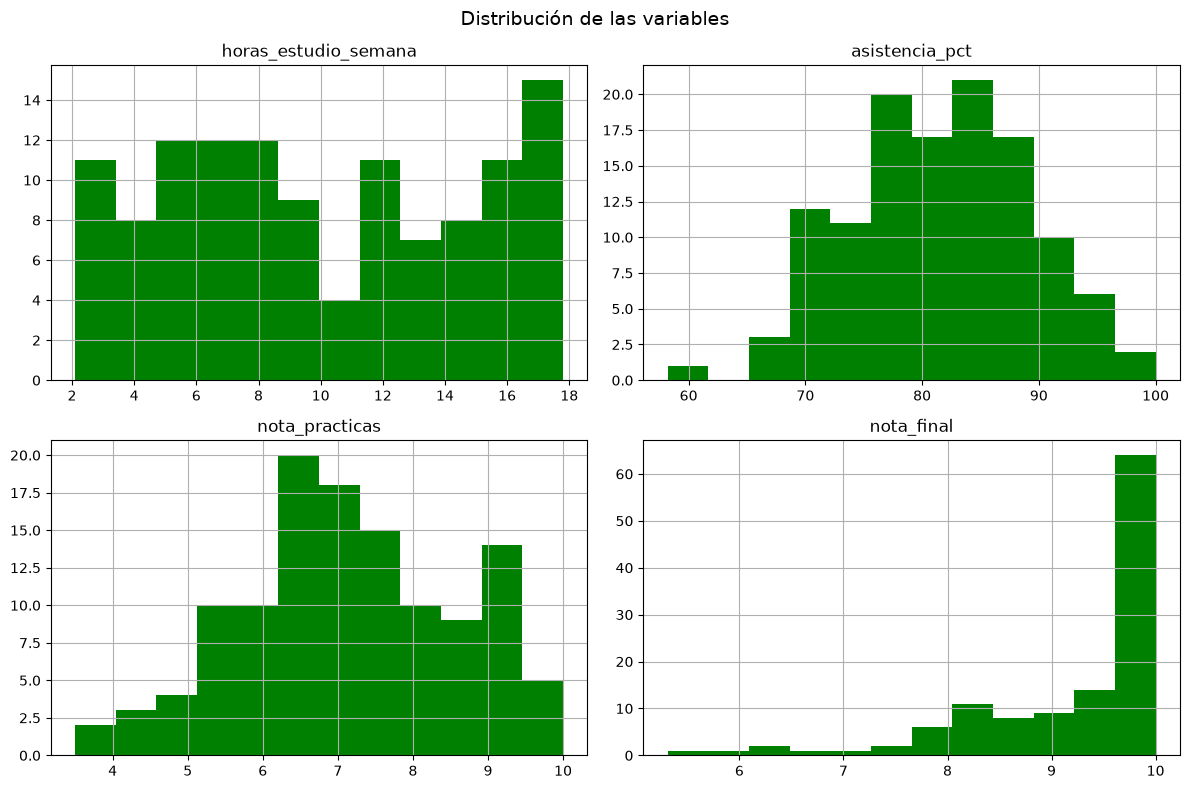

In [5]:
# Crea histogramas de las variables numéricas para observar la forma de sus distribuciones.
df.hist(figsize=(12, 8), bins=12, color = 'green') 
# Añade un título general al conjunto de histogramas.
plt.suptitle("Distribución de las variables", fontsize=14)
# Ajusta automáticamente los espacios para evitar que los elementos de los gráficos se solapen.
plt.tight_layout()
# Muestra en pantalla el gráfico creado.
plt.show()


Podemos crear cada uno de los gráficos de forma individual y poner la información relativa a cada uno de los ejes de las gráficas.

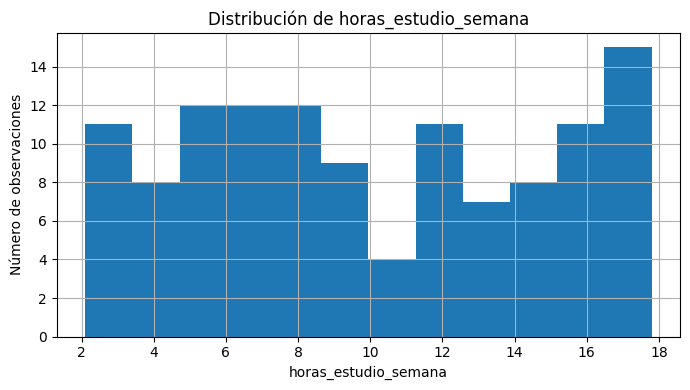

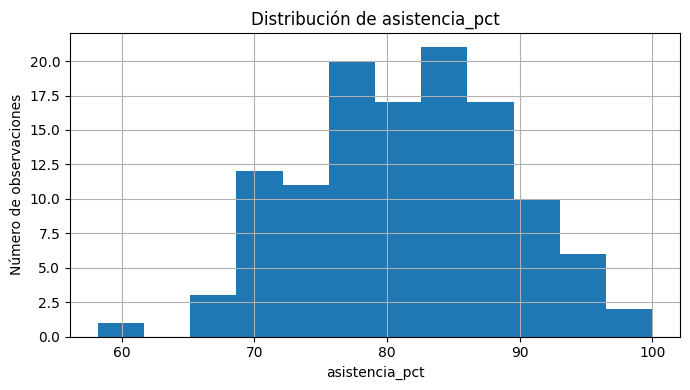

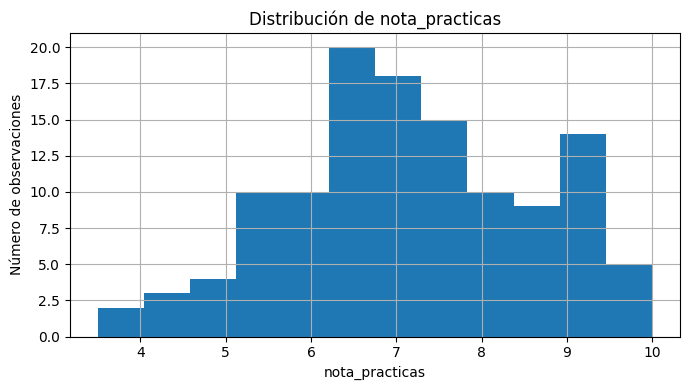

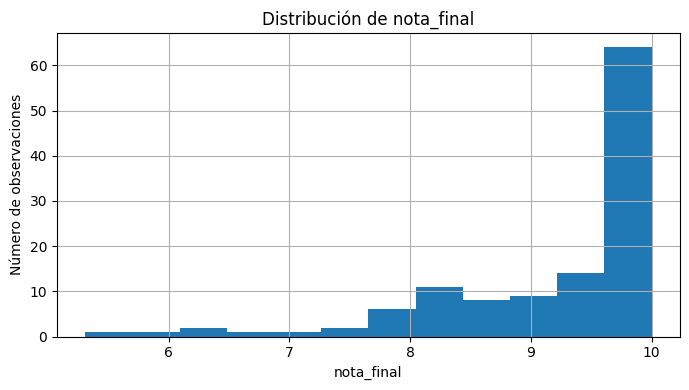

In [8]:
# Selecciona únicamente las columnas numéricas del conjunto de datos.
columnas_numericas = df.select_dtypes(include="number").columns

# Recorre una a una las variables numéricas.
for columna in columnas_numericas:

    # Crea una nueva figura para cada histograma.
    plt.figure(figsize=(7, 4))

    # Crea el histograma de la variable actual.
    plt.hist(df[columna], bins=12)

    # Etiqueta el eje horizontal con el nombre de la variable.
    plt.xlabel(columna)

    # Etiqueta el eje vertical indicando que representa el número de observaciones.
    plt.ylabel("Número de observaciones")

    # Añade un título indicando qué variable estamos estudiando.
    plt.title(f"Distribución de {columna}")

    # Ajusta los espacios del gráfico.
    plt.tight_layout()

    # Muestra la retícula
    plt.grid()

    # Muestra el histograma.
    plt.show()



## 3. La media, la mediana y la moda

La **media aritmética** resume la posición central de los datos.

Para los valores `4, 5, 6, 7, 8`:

**media = (4 + 5 + 6 + 7 + 8) / 5 = 6**

$$\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i$$

La pregunta que responde es:

> **¿Cuál sería el valor de cada observación si repartimos equitativamente el total?**


Media de horas de estudio: 10.0


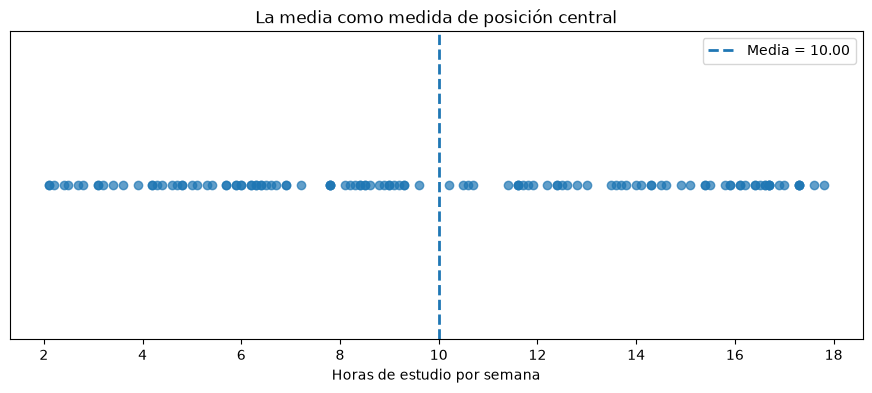

In [8]:
# Selecciona la variable horas de estudio y la guarda en x para trabajar con ella.
x = df["horas_estudio_semana"]
# Calcula la media aritmética de las horas de estudio.
media = x.mean()
# Muestra la media redondeada a dos decimales para facilitar su interpretación.
print("Media de horas de estudio:", round(media, 2))

# Crea una nueva figura y establece su tamaño en pulgadas.
plt.figure(figsize=(11,4))
# Representa cada observación de horas de estudio sobre una línea horizontal para visualizar su posición.
plt.scatter(x, np.zeros(len(x)), alpha=.7)
# Dibuja una línea vertical en la posición de la media para mostrar dónde se encuentra el valor central.
plt.axvline(media, linestyle="--", linewidth=2, label=f"Media = {media:.2f}")
# Oculta las marcas del eje vertical porque no aportan información relevante en este gráfico.
plt.yticks([])
# Etiqueta el eje horizontal indicando qué variable se está representando.
plt.xlabel("Horas de estudio por semana")
# Añade un título descriptivo al gráfico.
plt.title("La media como medida de posición central")
# Muestra la leyenda para identificar los elementos representados en el gráfico.
plt.legend()
# Muestra en pantalla el gráfico creado.
plt.show()


### Interpretación

La línea vertical es la media.

La media **no tiene por qué coincidir con una observación real**: es un resumen de todo el conjunto.

Además, los valores extremos pueden desplazarla.


La **mediana** es el valor de la variable que ocupa la posición central cuando todos los datos se encuentran ordenados de menor a mayor. Divide la distribución exactamente en dos partes iguales:
- El **50 %** de los datos tiene un valor menor o igual a la mediana.
- El **50 %** restante tiene un valor mayor o igual a la mediana.

**Propiedad clave:** A diferencia de la media, la mediana es una medida **robusta**, lo que significa que no se ve afectada drásticamente por valores extremadamente altos o bajos (outliers).

In [10]:
# Cálculo de la mediana para cada variable del conjunto de datos
mediana_horas = df['horas_estudio_semana'].median()
mediana_asistencia = df['asistencia_pct'].median()
mediana_practicas = df['nota_practicas'].median()
mediana_final = df['nota_final'].median()

print("--- Mediana de las variables ---")
print(f"Horas de estudio por semana: {mediana_horas:.2f}")
print(f"Porcentaje de asistencia:    {mediana_asistencia:.2f}%")
print(f"Nota de prácticas:           {mediana_practicas:.2f}")
print(f"Nota final:                  {mediana_final:.2f}")

--- Mediana de las variables ---
Horas de estudio por semana: 9.15
Porcentaje de asistencia:    81.60%
Nota de prácticas:           7.04
Nota final:                  9.86


La **moda** es el valor o categoría que aparece con mayor frecuencia en un conjunto de datos.

- **Datos discretos o cualitativos:** Es el valor exacto que más se repite.
- **Datos continuos:** En variables numéricas continuas con decimales, la moda se observa visualmente en la gráfica como el **pico máximo** de la distribución (la zona de mayor densidad de datos).
- Una distribución puede ser **unimodal** (un solo pico), **bimodal** (dos picos) o **multimodal** (varios picos).

In [20]:
# Cálculo de la moda con pandas para el conjunto de datos
print("--- Moda de las variables ---")
print(df.mode().iloc[0])

--- Moda de las variables ---
horas_estudio_semana     7.80
asistencia_pct          77.80
nota_practicas           6.41
nota_final              10.00
Name: 0, dtype: float64


Representación gráfica de las medidas de tendencia central

Al dibujar la **media**, la **mediana** y la **moda** sobre la distribución de los datos, podemos analizar la simetría de las variables.

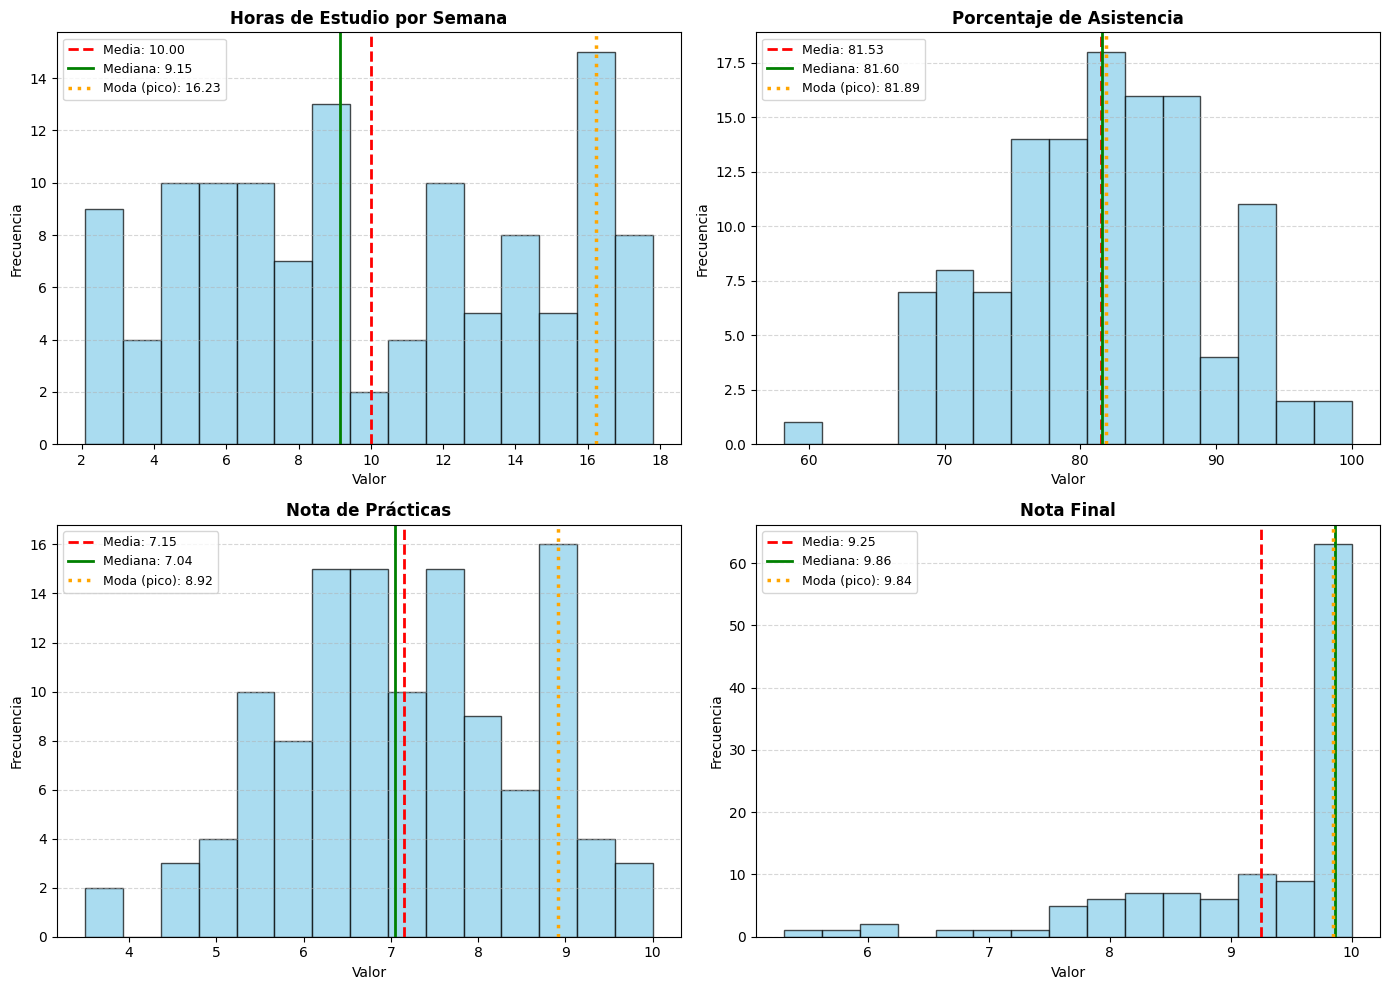

In [21]:
# Creación de una figura con subgráficos para representar Media, Mediana y Moda de las 4 variables
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
columnas = ['horas_estudio_semana', 'asistencia_pct', 'nota_practicas', 'nota_final']
titulos = ['Horas de Estudio por Semana', 'Porcentaje de Asistencia', 'Nota de Prácticas', 'Nota Final']

for ax, col, titulo in zip(axes.flatten(), columnas, titulos):
    datos = df[col]

    # Cálculos estadísticos
    media = datos.mean()
    mediana = datos.median()

    # Estimación del pico (moda gráfica) usando los intervalos del histograma
    counts, bins, _ = ax.hist(datos, bins=15, color='skyblue', edgecolor='black', alpha=0.7)
    max_idx = counts.argmax()
    moda_aprox = (bins[max_idx] + bins[max_idx + 1]) / 2

    # Líneas verticales para las estadísticas
    ax.axvline(media, color='red', linestyle='--', linewidth=2, label=f'Media: {media:.2f}')
    ax.axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.2f}')
    ax.axvline(moda_aprox, color='orange', linestyle=':', linewidth=2.5, label=f'Moda (pico): {moda_aprox:.2f}')

    # Configuración de los ejes y títulos
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel('Valor')
    ax.set_ylabel('Frecuencia')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 4. La varianza

La media indica **dónde está el centro**, pero necesitamos saber cuánto se separan los datos de ese centro.

La **varianza** mide esa dispersión:

1. calculamos la media;
2. calculamos cada desviación respecto a la media;
3. elevamos las desviaciones al cuadrado;
4. hacemos su media.

Para una población (Varianza Poblacional):

$$Var(X)=\sigma^2=\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2$$

Se utiliza cuando los datos represetan al total de la población.

Para una muestra (Varianza Muestral):

$$s^2=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2$$

Se utiliza cuando los datos representan una muestra de una población más grande.

En `pandas`, `var()` utiliza por defecto Varianza Muestral con  `ddof=1`.


In [11]:
# Crea un pequeño conjunto de cinco valores para explicar paso a paso cómo se calcula la varianza.
ejemplo = np.array([4,5,6,7,8])
# Ejecuta esta instrucción para realizar el paso indicado en el análisis de los datos.
media = ejemplo.mean()
# Construye una tabla de pandas para visualizar los valores y sus desviaciones respecto a la media.
tabla = pd.DataFrame({
    # Guarda en la columna valor los datos originales del ejemplo.
    "valor": ejemplo,
    # Calcula para cada dato cuánto se aleja de la media.
    "desviacion": ejemplo-media,
    # Eleva al cuadrado cada desviación para eliminar signos negativos y preparar el cálculo de la varianza.
    "desviacion_cuadrado": (ejemplo-media)**2
# Cierra la definición del diccionario usado para construir la tabla.
})
# Muestra la tabla resultante de forma legible dentro del cuaderno.
display(tabla)
# Muestra la media calculada para el pequeño ejemplo.
print("Media:", media)
# Calcula y muestra la varianza poblacional, considerando todos los valores como la población completa.
print("Varianza poblacional:", ejemplo.var())
# Calcula y muestra la varianza muestral, usando ddof=1 para aplicar la corrección de Bessel.
print("Varianza muestral:", ejemplo.var(ddof=1))


,valor,desviacion,desviacion_cuadrado
0,4,-2.0,4.0
1,5,-1.0,1.0
2,6,0.0,0.0
3,7,1.0,1.0
4,8,2.0,4.0


Media: 6.0
Varianza poblacional: 2.0
Varianza muestral: 2.5


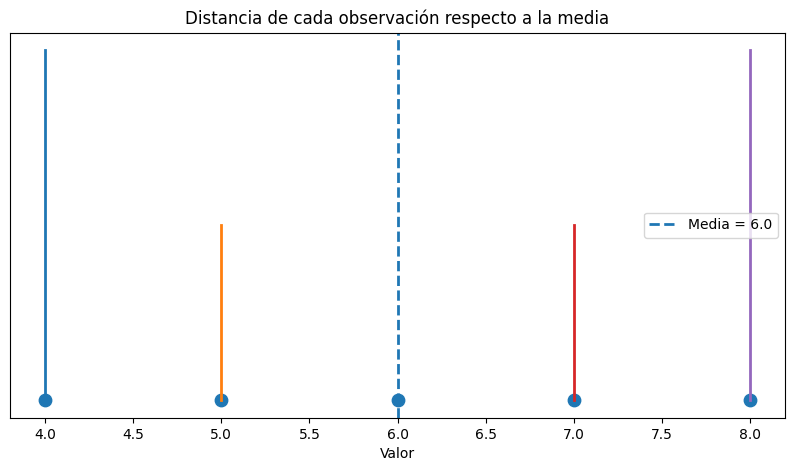

In [12]:
# Crea una nueva figura y establece su tamaño en pulgadas.
plt.figure(figsize=(10,5))
# Representa los valores del ejemplo sobre una línea horizontal.
plt.scatter(ejemplo, np.zeros(len(ejemplo)), s=80)
# Dibuja una línea vertical en la posición de la media para mostrar dónde se encuentra el valor central.
plt.axvline(media, linestyle="--", linewidth=2, label=f"Media = {media}")
# Recorre uno a uno los valores del ejemplo para dibujar su distancia hasta la media.
for valor in ejemplo:
    # Dibuja un segmento cuya longitud representa la distancia entre el valor y la media.
    plt.plot([valor, valor], [0, abs(valor-media)], linewidth=2)
# Oculta las marcas del eje vertical porque no aportan información relevante en este gráfico.
plt.yticks([])
# Etiqueta el eje horizontal con el nombre valor.
plt.xlabel("Valor")
# Añade un título descriptivo al gráfico.
plt.title("Distancia de cada observación respecto a la media")
# Muestra la leyenda para identificar los elementos representados en el gráfico.
plt.legend()
# Muestra en pantalla el gráfico creado.
plt.show()


Para el ejemplo de las calificaciones:

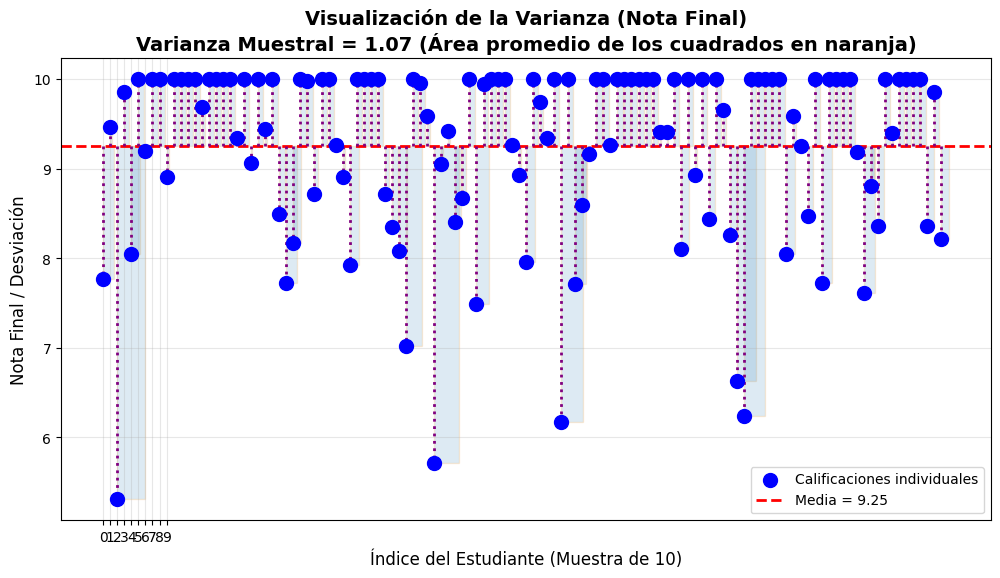

In [24]:
# Seleccionamos una muestra pequeña de 10 estudiantes para que el gráfico sea muy claro
muestra_calificaciones = df["nota_final"].to_numpy()
media_calificaciones = muestra_calificaciones.mean()
varianza_muestra = muestra_calificaciones.var(ddof=1) # Varianza muestral

plt.figure(figsize=(12, 6))

# Dibujamos las notas individuales
plt.scatter(range(len(muestra_calificaciones)), muestra_calificaciones, color='blue', s=100, zorder=5, label='Calificaciones individuales')

# Línea horizontal para la media
plt.axhline(media_calificaciones, color='red', linestyle='--', linewidth=2, label=f'Media = {media_calificaciones:.2f}')

# Dibujamos la distancia y el cuadrado de la desviación (varianza)
for idx, nota in enumerate(muestra_calificaciones):
    desviacion = nota - media_calificaciones
    # Línea que une el punto con la media
    plt.plot([idx, idx], [media_calificaciones, nota], color='purple', linestyle=':', linewidth=2)

    # Dibujamos un rectángulo semi-transparente para representar la desviación al cuadrado
    # El ancho y el alto del rectángulo serán igual a la desviación absoluta
    lado = abs(desviacion)
    rect = plt.Rectangle(
        (idx, min(nota, media_calificaciones)),
        lado, lado, alpha=0.15, edgecolor='darkorange', linestyle='-'
    )
    plt.gca().add_patch(rect)

plt.title(f"Visualización de la Varianza (Nota Final)\nVarianza Muestral = {varianza_muestra:.2f} (Área promedio de los cuadrados en naranja)", fontsize=14, fontweight='bold')
plt.xlabel("Índice del Estudiante (Muestra de 10)", fontsize=12)
plt.ylabel("Nota Final / Desviación", fontsize=12)
plt.xticks(range(10))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Interpretación de la varianza

- **Varianza pequeña** → valores relativamente concentrados.
- **Varianza grande** → valores más dispersos.

La varianza queda expresada en **unidades al cuadrado**.

Por eso también utilizaremos la desviación típica, que devuelve la escala original.


Grupo A -> media: 6.0 varianza: 0.5
Grupo B -> media: 6.0 varianza: 8.0


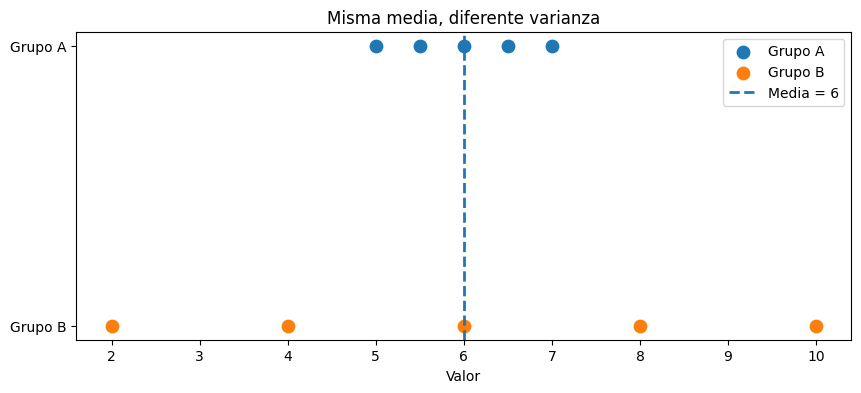

In [13]:
# Crea un primer grupo de datos con valores relativamente próximos entre sí.
grupo_a = np.array([5,5.5,6,6.5,7])
# Crea un segundo grupo con valores más dispersos, manteniendo la misma media.
grupo_b = np.array([2,4,6,8,10])

# Calcula y muestra la media y la varianza del grupo A para comparar su dispersión.
print("Grupo A -> media:", grupo_a.mean(), "varianza:", grupo_a.var())
# Calcula y muestra la media y la varianza del grupo B para comparar su dispersión.
print("Grupo B -> media:", grupo_b.mean(), "varianza:", grupo_b.var())

# Crea una nueva figura y establece su tamaño en pulgadas.
plt.figure(figsize=(10,4))
# Representa visualmente los valores del grupo A.
plt.scatter(grupo_a, np.ones(len(grupo_a)), s=80, label="Grupo A")
# Representa visualmente los valores del grupo B.
plt.scatter(grupo_b, np.zeros(len(grupo_b)), s=80, label="Grupo B")
# Dibuja una línea vertical en la posición de la media para mostrar dónde se encuentra el valor central.
plt.axvline(6, linestyle="--", linewidth=2, label="Media = 6")
# Personaliza las marcas del eje vertical para identificar los dos grupos.
plt.yticks([0,1], ["Grupo B","Grupo A"])
# Etiqueta el eje horizontal con el nombre valor.
plt.xlabel("Valor")
# Añade un título descriptivo al gráfico.
plt.title("Misma media, diferente varianza")
# Muestra la leyenda para identificar los elementos representados en el gráfico.
plt.legend()
# Muestra en pantalla el gráfico creado.
plt.show()


# 5. Desviación típica

La **desviación típica** es una medida que nos indica cuánto se alejan, en promedio, los valores de una variable respecto de su media.

Está directamente relacionada con la varianza:

$$
\sigma = \sqrt{\sigma^2}
$$

Por tanto:

- **Varianza** → promedio de las desviaciones al cuadrado.
- **Desviación típica** → raíz cuadrada de la varianza.

La principal ventaja de la desviación típica es que se expresa en las **mismas unidades que la variable original**.

Por ejemplo, si estudiamos las horas de estudio:

- Media = 8 horas.
- Varianza = 4 horas².
- Desviación típica = 2 horas.

Podemos interpretar que los valores se encuentran, aproximadamente, a una distancia típica de **2 horas respecto de la media**.

> Cuanto mayor sea la desviación típica, mayor será la dispersión de los datos.

In [25]:
# Selecciona la variable que queremos analizar.
x = df["horas_estudio_semana"]

# Calcula la media de la variable.
media = x.mean()

# Calcula la varianza.
varianza = x.var()

# Calcula la desviación típica.
desviacion_tipica = x.std()

# Muestra los resultados.
print("Media:", round(media, 2))
print("Varianza:", round(varianza, 2))
print("Desviación típica:", round(desviacion_tipica, 2))

Media: 10.0
Varianza: 22.71
Desviación típica: 4.77


## 6. La covarianza

Ahora estudiamos **dos variables simultáneamente**.

Pregunta:

> ¿Existe relación entre las horas de estudio y la nota final?

La **covarianza** indica si dos variables tienden a variar conjuntamente.

$$Cov(X,Y)=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})$$

La clave inicial es su **signo**:

- positiva → tienden a crecer juntas;
- negativa → cuando una crece, la otra tiende a disminuir;
- cercana a cero → no hay una relación lineal clara.


Covarianza: 3.536


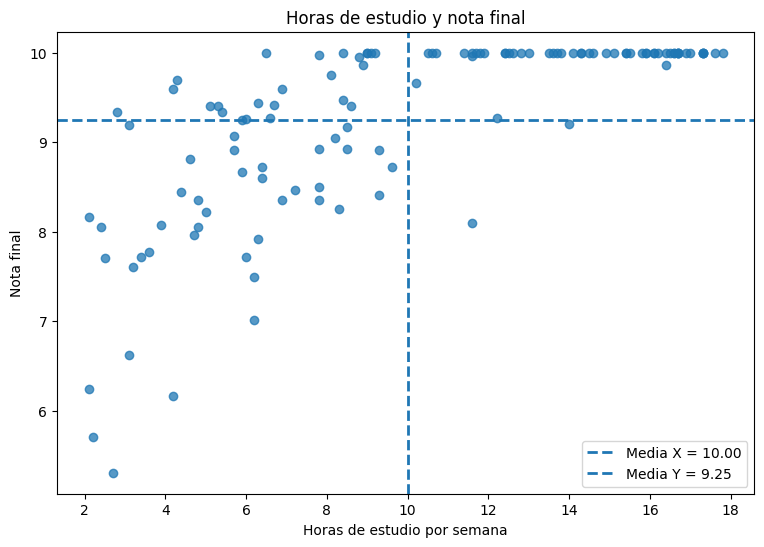

In [15]:
# Selecciona la variable horas de estudio y la guarda en x para trabajar con ella.
x = df["horas_estudio_semana"]
# Selecciona la nota final como variable Y para estudiar la relación entre ambas variables.
y = df["nota_final"]

# Calcula y muestra la covarianza entre las horas de estudio y la nota final.
print("Covarianza:", round(x.cov(y), 3))

# Crea una nueva figura y establece su tamaño en pulgadas.
plt.figure(figsize=(9,6))
# Representa cada alumno mediante un punto según sus horas de estudio y su nota final.
plt.scatter(x, y, alpha=.75)
# Dibuja una línea vertical en la posición de la media para mostrar dónde se encuentra el valor central.
plt.axvline(x.mean(), linestyle="--", linewidth=2, label=f"Media X = {x.mean():.2f}")
# Marca la media de la nota final en el eje vertical.
plt.axhline(y.mean(), linestyle="--", linewidth=2, label=f"Media Y = {y.mean():.2f}")
# Etiqueta el eje horizontal indicando qué variable se está representando.
plt.xlabel("Horas de estudio por semana")
# Etiqueta el eje vertical indicando que representa la nota final.
plt.ylabel("Nota final")
# Añade un título descriptivo al gráfico.
plt.title("Horas de estudio y nota final")
# Muestra la leyenda para identificar los elementos representados en el gráfico.
plt.legend()
# Muestra en pantalla el gráfico creado.
plt.show()


# Las cuatro zonas del gráfico

Las medias dividen el gráfico en cuatro zonas.

| X respecto a su media | Y respecto a su media | Producto `(X-media)·(Y-media)` |
|---|---|---|
| positiva | positiva | positivo |
| negativa | negativa | positivo |
| negativa | positiva | negativo |
| positiva | negativa | negativo |

Si predominan los productos positivos, la covarianza tiende a ser positiva.

Si predominan los negativos, tiende a ser negativa.

# Las cuatro zonas de la covarianza

Para entender el signo de la covarianza vamos a dividir el gráfico en cuatro zonas.

Tenemos dos variables:

- **X** → horas de estudio por semana.
- **Y** → nota final.

Primero calculamos la media de cada variable y dibujamos:

- una línea vertical en la media de X;
- una línea horizontal en la media de Y.

Estas dos líneas dividen el gráfico en cuatro zonas.

---

## ¿Qué hacemos con cada punto?

Para cada observación calculamos dos desviaciones:

$$
x_i-\bar{x}
$$

Indica si el valor de X está por encima o por debajo de su media.

Y:

$$
y_i-\bar{y}
$$

Indica si el valor de Y está por encima o por debajo de su media.

Después multiplicamos ambas desviaciones:

$$
(x_i-\bar{x})(y_i-\bar{y})
$$

Este producto es el que determina si ese punto aporta **positivamente o negativamente** a la covarianza.

---

## Zona superior derecha: aporte positivo

En esta zona:

$$
X > \bar{X}
$$

y

$$
Y > \bar{Y}
$$

Por tanto:

$$
(x_i-\bar{x})>0
$$

y

$$
(y_i-\bar{y})>0
$$

Al multiplicar:

$$
(+)\times(+)=+
$$

**El punto aporta positivamente a la covarianza.**

Interpretación: el alumno estudia más horas que la media y obtiene una nota superior a la media.

---

## Zona superior izquierda: aporte negativo

En esta zona:

$$
X < \bar{X}
$$

pero

$$
Y > \bar{Y}
$$

Por tanto:

$$
(x_i-\bar{x})<0
$$

y

$$
(y_i-\bar{y})>0
$$

Al multiplicar:

$$
(-)\times(+) = -
$$

**El punto aporta negativamente a la covarianza.**

Interpretación: el alumno estudia menos horas que la media pero obtiene una nota superior a la media.

---

## Zona inferior izquierda: aporte positivo

En esta zona:

$$
X < \bar{X}
$$

y

$$
Y < \bar{Y}
$$

Por tanto:

$$
(x_i-\bar{x})<0
$$

y

$$
(y_i-\bar{y})<0
$$

Al multiplicar:

$$
(-)\times(-)=+
$$

**El punto aporta positivamente a la covarianza.**

Interpretación: el alumno estudia menos horas que la media y obtiene una nota inferior a la media.

Aunque las dos desviaciones son negativas, su producto es positivo.

---

## Zona inferior derecha: aporte negativo

En esta zona:

$$
X > \bar{X}
$$

pero

$$
Y < \bar{Y}
$$

Por tanto:

$$
(x_i-\bar{x})>0
$$

y

$$
(y_i-\bar{y})<0
$$

Al multiplicar:

$$
(+)\times(-)=-
$$

**El punto aporta negativamente a la covarianza.**

Interpretación: el alumno estudia más horas que la media pero obtiene una nota inferior a la media.

---

## Resumen

| Zona | X respecto a la media | Y respecto a la media | Producto | Aporte |
|---|---|---|---|---|
| Superior derecha | + | + | + | Positivo |
| Superior izquierda | − | + | − | Negativo |
| Inferior izquierda | − | − | + | Positivo |
| Inferior derecha | + | − | − | Negativo |

Por tanto:

**Mismo signo en las desviaciones → aporte positivo.**

**Signo diferente en las desviaciones → aporte negativo.**

La covarianza se obtiene combinando los aportes de **todos los puntos**:

$$
Cov(X,Y)=
\frac{1}{n-1}
\sum_{i=1}^{n}
(x_i-\bar{x})(y_i-\bar{y})
$$

Si predominan los aportes positivos:

$$
Cov(X,Y)>0
$$

Si predominan los aportes negativos:

$$
Cov(X,Y)<0
$$

Si los aportes positivos y negativos se compensan:

$$
Cov(X,Y)\approx0
$$

> **Importante:** no basta con contar cuántos puntos hay en cada zona. También importa cuánto se aleja cada punto de las medias.

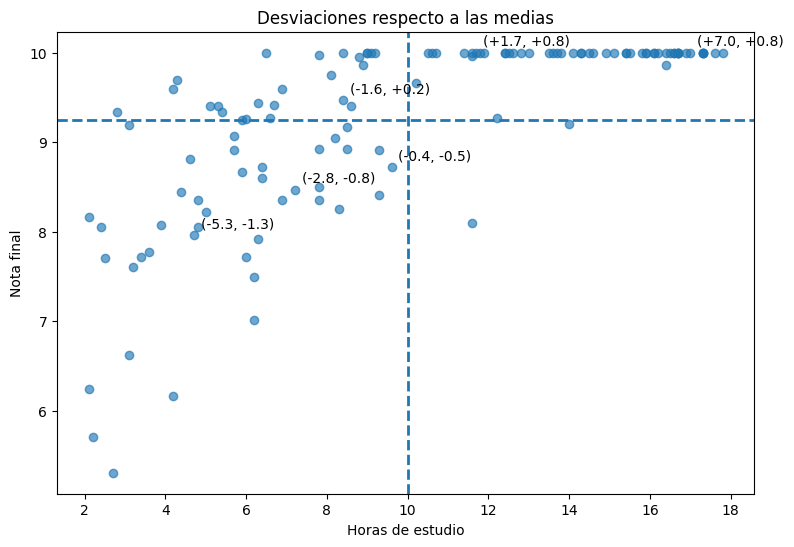

In [16]:
# Convierte las horas de estudio en un array de NumPy para realizar cálculos elemento a elemento.
x = df["horas_estudio_semana"].to_numpy()
# Convierte las notas finales en un array de NumPy para realizar cálculos elemento a elemento.
y = df["nota_final"].to_numpy()
# Calcula las medias de X e Y y las guarda en mx y my.
mx, my = x.mean(), y.mean()

# Crea una nueva figura y establece su tamaño en pulgadas.
plt.figure(figsize=(9,6))
# Representa cada alumno mediante un punto según sus horas de estudio y su nota final.
plt.scatter(x, y, alpha=.65)
# Dibuja una línea vertical en la posición de la media para mostrar dónde se encuentra el valor central.
plt.axvline(mx, linestyle="--", linewidth=2)
# Dibuja una línea vertical en la posición de la media para mostrar dónde se encuentra el valor central.
plt.axhline(my, linestyle="--", linewidth=2)

# Selecciona algunas observaciones concretas para explicar visualmente sus desviaciones respecto a las medias.
for i in [1,15,20,40,60,100]:
    # Añade una anotación de texto junto a cada punto seleccionado.
    plt.annotate(
        # Calcula y muestra las desviaciones de X e Y respecto a sus respectivas medias.
        f"({x[i]-mx:+.1f}, {y[i]-my:+.1f})",
        # Indica las coordenadas del punto que se quiere etiquetar.
        (x[i],y[i]), xytext=(5,5), textcoords="offset points"
    # Ejecuta esta instrucción para realizar el paso indicado en el análisis de los datos.
    )

# Etiqueta el eje horizontal indicando qué variable se está representando.
plt.xlabel("Horas de estudio")
# Etiqueta el eje vertical indicando que representa la nota final.
plt.ylabel("Nota final")
# Añade un título descriptivo al gráfico.
plt.title("Desviaciones respecto a las medias")
# Muestra en pantalla el gráfico creado.
plt.show()


### ¿Qué significa una etiqueta como `(+2.0, -0.5)`?

La observación está:

- 2 unidades por encima de la media de X;
- 0,5 unidades por debajo de la media de Y.

Su contribución al producto de desviaciones sería:

`(+2.0) × (-0.5) = -1.0`

Por tanto, contribuye **negativamente** a la covarianza.


Matriz de covarianzas:


,horas_estudio_semana,asistencia_pct,nota_practicas,nota_final
horas_estudio_semana,22.71,2.41,-0.73,3.54
asistencia_pct,2.41,58.85,1.86,2.60
nota_practicas,-0.73,1.86,2.01,0.36
nota_final,3.54,2.60,0.36,1.07


Matriz de correlaciones:


,horas_estudio_semana,asistencia_pct,nota_practicas,nota_final
horas_estudio_semana,1.00,0.07,-0.11,0.72
asistencia_pct,0.07,1.00,0.17,0.33
nota_practicas,-0.11,0.17,1.00,0.25
nota_final,0.72,0.33,0.25,1.00


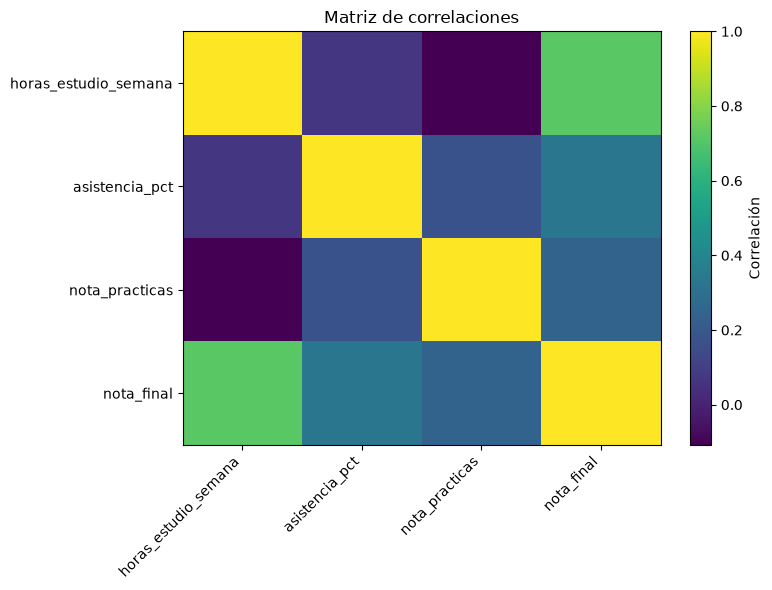

In [4]:
# Escribe un encabezado para presentar la matriz de covarianzas.
print("Matriz de covarianzas:")
# Calcula la matriz de covarianzas, redondea sus valores a dos decimales y la muestra.
display(df.cov().round(2))

# Escribe un encabezado para presentar la matriz de correlaciones.
print("Matriz de correlaciones:")
# Calcula la matriz de correlaciones, redondea sus valores a dos decimales y la muestra.
display(df.corr().round(2))

# Crea una nueva figura y establece su tamaño en pulgadas.
plt.figure(figsize=(8,6))
# Representa la matriz de correlaciones como una imagen para facilitar su lectura visual.
plt.imshow(df.corr(), aspect="auto")
# Añade una barra de referencia que permite interpretar visualmente los valores de correlación.
plt.colorbar(label="Correlación")
# Coloca los nombres de las variables en el eje horizontal y los gira para facilitar su lectura.
plt.xticks(range(len(df.columns)), df.columns, rotation=45, ha="right")
# Coloca los nombres de las variables en el eje vertical de la matriz.
plt.yticks(range(len(df.columns)), df.columns)
# Añade un título descriptivo al gráfico.
plt.title("Matriz de correlaciones")
# Ajusta automáticamente los espacios para evitar que los elementos de los gráficos se solapen.
plt.tight_layout()
# Muestra en pantalla el gráfico creado.
plt.show()


# 7. Correlación

La **correlación** mide la intensidad y la dirección de la relación lineal entre dos variables.

A diferencia de la covarianza, la correlación siempre está comprendida entre:

$$
-1 \leq r \leq 1
$$

Su interpretación básica es:

- **r ≈ 1** → relación lineal positiva fuerte.
- **r ≈ 0** → no existe una relación lineal clara.
- **r ≈ -1** → relación lineal negativa fuerte.

Por ejemplo, si estudiamos las variables:

- **X** → horas de estudio por semana.
- **Y** → nota final.

Una correlación positiva indicaría que, en general, cuando aumentan las horas de estudio también tiende a aumentar la nota.

Una correlación negativa indicaría que cuando aumentan las horas de estudio tiende a disminuir la nota.

Una correlación cercana a cero indicaría que no observamos una relación lineal clara entre ambas variables.

> **Importante:** correlación no significa causalidad. Que dos variables estén relacionadas no demuestra que una sea la causa de la otra.

## ¿Cómo se calcula?

La correlación de Pearson se puede expresar a partir de la covarianza:

$$
r =
\frac{Cov(X,Y)}
{\sigma_X \sigma_Y}
$$

Es decir, la covarianza se divide por las desviaciones típicas de las dos variables.

Esto hace que el resultado quede **normalizado entre -1 y 1**.

Por eso la correlación resulta más fácil de comparar e interpretar que la covarianza.

In [13]:
# Selecciona la variable X.
x = df["horas_estudio_semana"]

# Selecciona la variable Y.
y = df["nota_final"]

# Calcula la correlación de Pearson entre X e Y.
correlacion = x.corr(y)

# Muestra el resultado.
print("Correlación de Pearson:", round(correlacion, 3))

Correlación de Pearson: 0.717


## ¿Cómo interpretamos el valor?

Podemos utilizar esta orientación:

| Correlación | Interpretación aproximada |
|---:|---|
| **r ≈ 1** | Relación lineal positiva muy fuerte |
| **r > 0** | Relación lineal positiva |
| **r ≈ 0** | Relación lineal muy débil o inexistente |
| **r < 0** | Relación lineal negativa |
| **r ≈ -1** | Relación lineal negativa muy fuerte |

Por ejemplo:

$$
r = 0.85
$$

indica una relación lineal positiva fuerte.

En cambio:

$$
r = -0.80
$$

indica una relación lineal negativa fuerte.

Y:

$$
r = 0.05
$$

indica que prácticamente no observamos una relación lineal.

**El signo indica la dirección y el valor absoluto indica la intensidad de la relación lineal.**

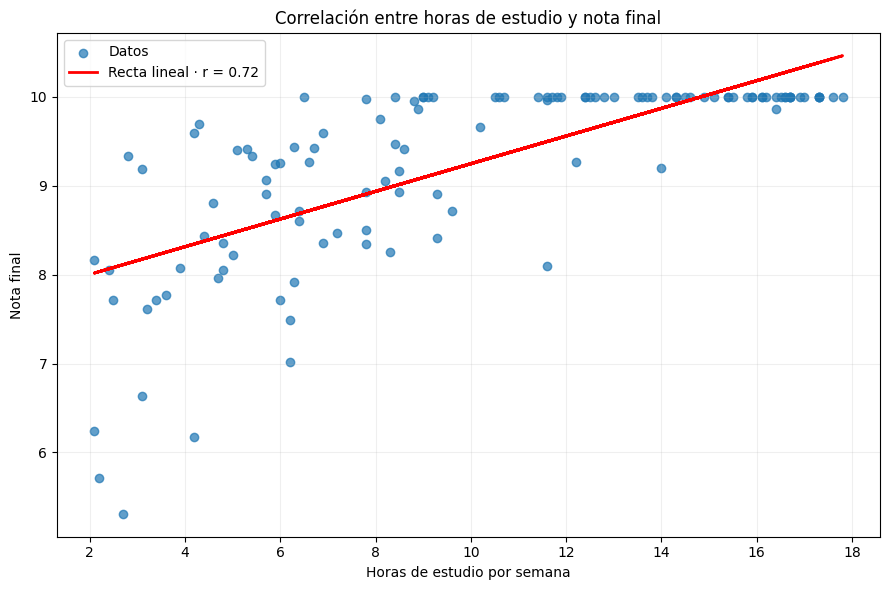

In [19]:
# Selecciona las variables que queremos comparar.
x = df["horas_estudio_semana"]
y = df["nota_final"]

# Calcula la correlación de Pearson.
correlacion = x.corr(y)

# Calcula la recta que mejor se ajusta a los datos.
pendiente, intercepto = np.polyfit(x, y, 1)

# Calcula los valores de Y correspondientes a la recta.
y_pred = pendiente * x + intercepto

# Crea una figura nueva.
plt.figure(figsize=(9, 6))

# Representa los datos como puntos.
plt.scatter(x, y, alpha=0.7, label="Datos")

# Representa la recta de tendencia.
plt.plot(
    x,
    y_pred,
    linewidth=2,
    color="red",
    label=f"Recta lineal · r = {correlacion:.2f}"
)

# Etiqueta el eje X.
plt.xlabel("Horas de estudio por semana")

# Etiqueta el eje Y.
plt.ylabel("Nota final")

# Añade el título.
plt.title("Correlación entre horas de estudio y nota final")

# Muestra la leyenda.
plt.legend()

# Añade una cuadrícula para facilitar la lectura.
plt.grid(alpha=0.2)

# Ajusta los márgenes.
plt.tight_layout()

# Muestra el gráfico.
plt.show()

# Cierra la figura.
plt.close()

Comprueba cómo cambia la correlación según la posición de los puntos a través de este gráfico interactivo:

[Gráfico Correlación](https://chatgpt.com/s/w_6ab9707d4cd08191a0e052114bee15db)

## Una idea importante

La correlación nos permite resumir una nube de puntos mediante un único número:

**Dirección**

- `r > 0` → relación positiva.
- `r < 0` → relación negativa.

**Intensidad**

- `|r|` cercano a 1 → relación lineal fuerte.
- `|r|` cercano a 0 → relación lineal débil.

Por ejemplo:

$$
r = 0.90
$$

→ relación positiva fuerte.

$$
r = -0.90
$$

→ relación negativa fuerte.

$$
r = 0.10
$$

→ relación lineal muy débil.

> **La correlación mide relación lineal. Una correlación cercana a 0 no significa necesariamente que no exista ningún tipo de relación entre las variables.**

# 8. Resumen

| Concepto | ¿Qué nos dice? |
|---|---|
| **Media** | posición central |
| **Varianza** | dispersión de una variable |
| **Desviación Típica** | media de la dispersión respecto a la media |
| **Covarianza** | cómo dos variables varían conjuntamente |
| **Correlación** | relación lineal normalizada |

## Idea fundamental

Antes de entrenar un modelo de Machine Learning debemos **conocer y describir los datos**.

En las siguientes sesiones iremos de:

**estadística → correlaciones → selección de variables → preparación → modelos de Machine Learning**


# Actividad inicial

Sin cambiar el CSV:

1. **Calcula la media y la desviación típica de cada variable numérica.**
   ¿Cuál presenta mayor dispersión?

2. **Representa gráficamente dos variables que te parezcan interesantes.**

3. **Calcula la covarianza** entre esas dos variables.

4. **Interpreta el signo de la covarianza.**
   ¿Qué indica sobre la relación entre las dos variables?

5. **Compara la covarianza con la gráfica.**
   ¿Coinciden las conclusiones obtenidas mediante el cálculo y mediante la representación gráfica?

6. **Calcula la correlación** entre esas dos variables.
   ¿Qué diferencia encuentras entre la covarianza y la correlación?

7. **Consulta la matriz de correlaciones** de todas las variables numéricas.
   ¿Qué relaciones te parecen más interesantes?

---

### Para cada respuesta intenta explicar:

> **qué observas → qué medida lo resume → qué significa**

